In this seminar, we will use the PyTorch skills introduced in the previous class. We will explore KL divergence, compare it with other ways of measuring distribution mismatch, and discuss the strengths and weaknesses of each choice.

We will also study several practical metrics for evaluating image generative models.


In [1]:
import matplotlib.pyplot as plt
from matplotlib import style
style.use('fivethirtyeight')
%matplotlib inline

import numpy as np


import torch
from torch import distributions as distrs
from torch.distributions.multivariate_normal import MultivariateNormal

from IPython.display import clear_output

# Reproducible classroom results
np.random.seed(0)
torch.manual_seed(0)

The following helper functions create, sample and plot two-dimensional distributions.

In the two-dimensional examples, the variable `sigma` actually stores a **covariance matrix**, not a standard deviation. We optimize it directly only to keep the demonstration simple. In a real model, parameterize the covariance through a Cholesky factor so that it always remains positive definite.


In [2]:
# Plot samples from a two-dimensional distribution
def plot_2d_dots(dots, color='blue', label='None'):
    plt.ylim(-10, 10)
    plt.xlim(-10, 10)
    plt.scatter(dots[:, 0], dots[:, 1], s=1, c=color, label=label)

def create_distr(mu, sigma):
    return distrs.MultivariateNormal(mu, sigma)

# Wrap the distribution parameters in trainable PyTorch tensors
def get_parameters(mu=0., sigma=1.):
    train_mu = torch.Tensor([mu, mu])
    train_mu.requires_grad=True
    train_sigma = torch.Tensor([[sigma, 0.0],
                                [0.0, sigma]])
    train_sigma.requires_grad=True
    return train_mu, train_sigma

def sample(d, num):
    return d.sample(torch.Size([num]))

# Chapter 1: fitting a unimodal two-dimensional distribution

### Target distribution


In [3]:
mu = torch.Tensor([-5, -5])
sigma = torch.Tensor([[1., 0.0],
                      [0.0, 1.]])

target = create_distr(mu, sigma)
# x - samples from the target distribution
x = sample(target, 1000)
# px = p(x) = probability of target samples for the target distribution
px = target.log_prob(x).exp()

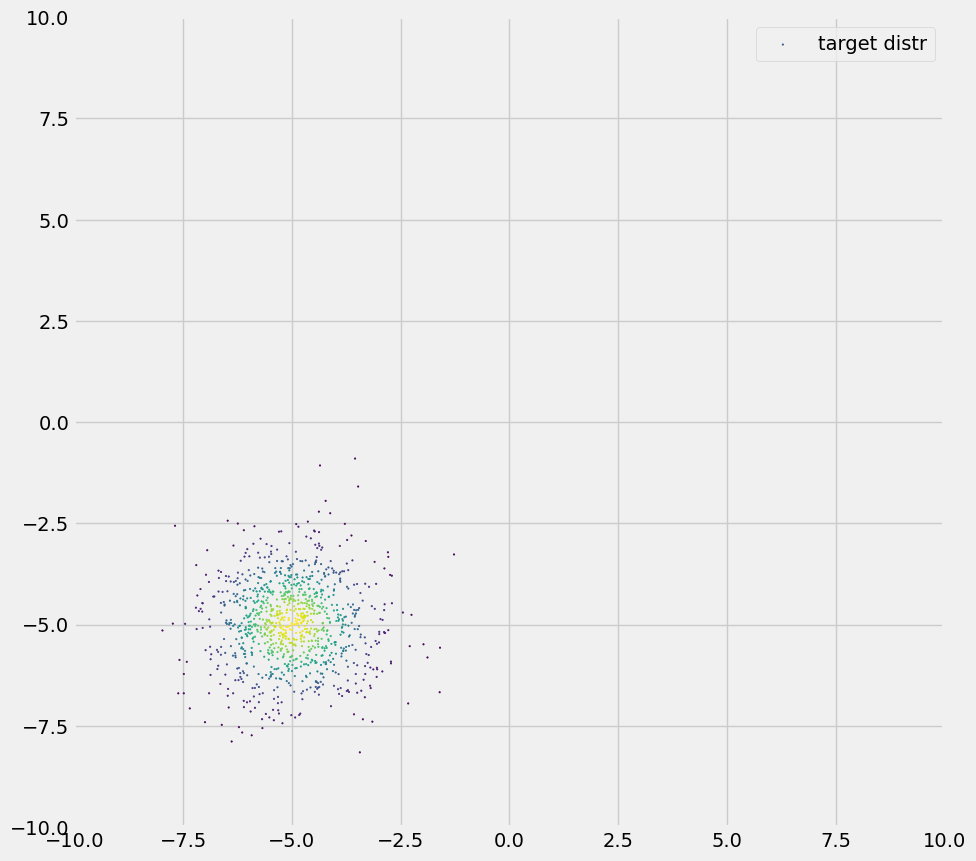

In [4]:
plt.figure(figsize=(10, 10))
plot_2d_dots(x, color=px, label='target distr')
plt.legend()
plt.show()

### Our approximation to the target distribution

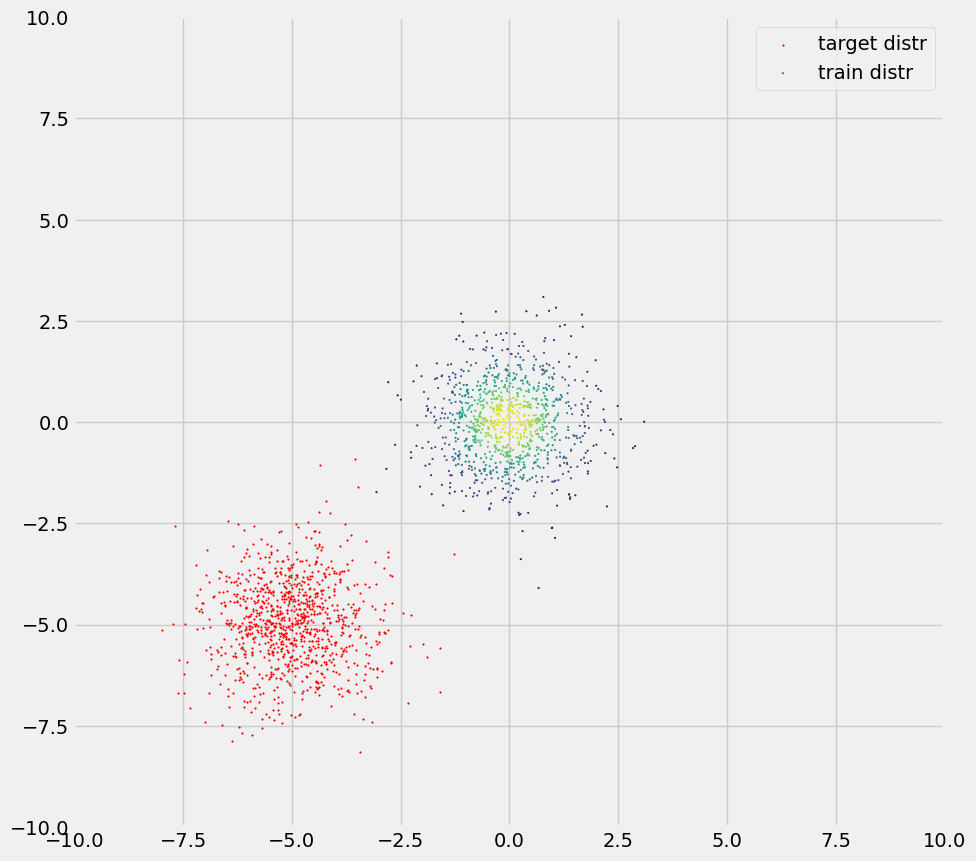

In [5]:
# starting points
train_mu, train_sigma = get_parameters()

Q = create_distr(train_mu, train_sigma)
q_sample = sample(Q, 1000)
plt.figure(figsize=(10, 10))
plot_2d_dots(x, color='r', label='target distr')
plot_2d_dots(q_sample, color= Q.log_prob(q_sample).exp().detach(), label='train distr')

plt.legend()
plt.show()

In [6]:
def kl_loss(px, qx, weights=None):
    """
    px - torch.Tensor
    qx - torch.Tensor 
    weigths - object weights (when importance sampling is used)
    """
    # Clamp for the numerical stability 
    px, qx = px.clamp(min=1e-7), qx.clamp(min=1e-7)
    if weights is None: weights = torch.ones_like(px)
    return torch.mean(weights*px * (px.log() - qx.log())) # YOUR CODE

# train_mu and train_sigma are TRAINABLE parameters
train_mu, train_sigma = get_parameters()

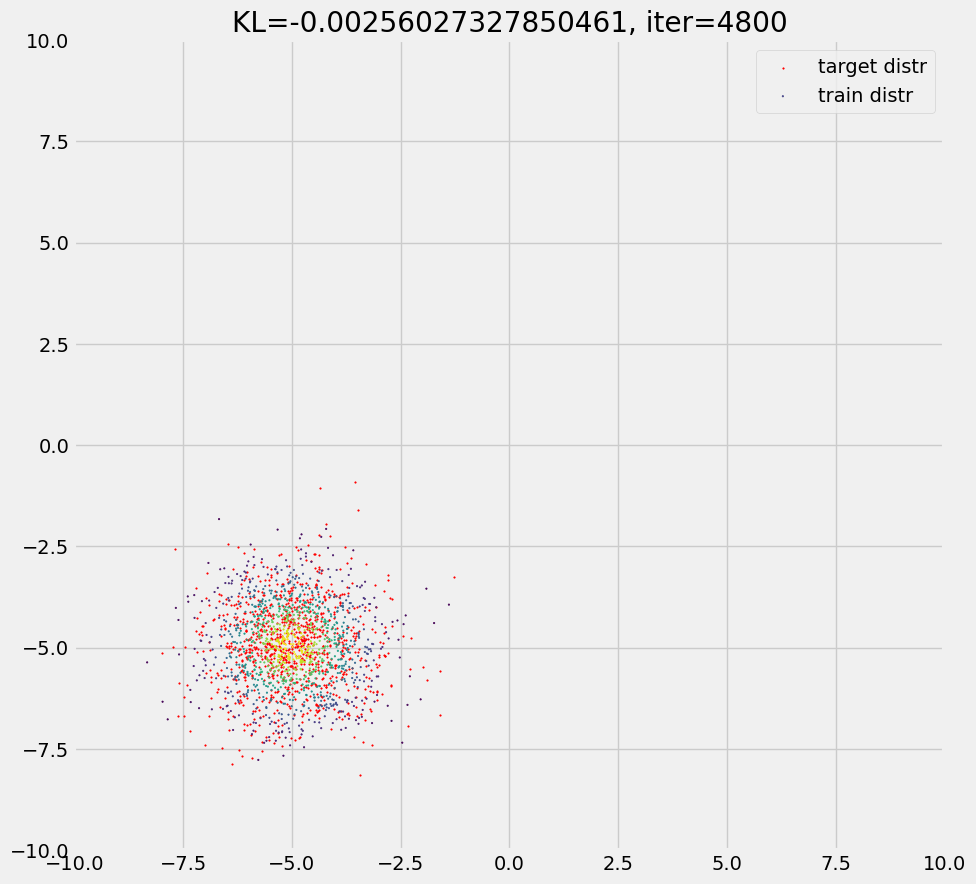

In [7]:
# Try replacing SGD with Adam
optim = torch.optim.SGD([train_mu, train_sigma], lr=0.1)

for i in range(5000):
    optim.zero_grad()
    Q = create_distr(train_mu, train_sigma)
    # qx = q(x) = probability of target samples for the train distribution
    qx = Q.log_prob(x).exp()
    loss = kl_loss(px, qx, 1./px)
    loss.backward()
    optim.step()
    if i % 200 == 0:
        # plot pdfs
        clear_output(True)
        plt.figure(figsize=(10, 10))
        plt.title(f'KL={loss.item()}, iter={i}')
        plot_2d_dots(x, color='r', label='target distr')
        # q_sample - samples from the train distribution, just for visualization
        q_sample = sample(Q, 1000)
        plot_2d_dots(q_sample, color= Q.log_prob(q_sample).exp().detach(), label='train distr')
        plt.legend()
        plt.show()

### After Experiment 1 — Forward KL with a one-mode target

**What to notice**

- The learned red samples should overlap the blue target samples.
- The learned mean should move close to (-5, -5), and the covariance should become close to the identity matrix.
- The exact KL divergence is never negative, although a noisy Monte Carlo estimate can occasionally be slightly below zero.

**What students should learn**

- When the model family is expressive enough—a Gaussian fitting a Gaussian—forward KL can recover the target well.
- The optimizer improves parameters by following gradients computed from sampled points.

**Ask the class**

What changes first during training: the center of the cloud, its size, or its tilt?


# Chapter 2: fitting a bimodal target with a unimodal model

The target has two modes, but the trainable model is still a single Gaussian. No objective can make this model represent both modes exactly. We will observe the compromise preferred by forward KL.

### Target distribution


In [8]:
target1 = create_distr(torch.Tensor([-5, -5]), torch.Tensor([[1., 0.0], [0.0, 1.]]))
target2 = create_distr(torch.Tensor([4, 3]), torch.Tensor([[1., 0.0], [0.0, 1.]]))

# Equal-weight mixture: P = 0.5 * P1 + 0.5 * P2
x = torch.cat([sample(target1, 1000), sample(target2, 1000)])
px = 0.5 * target1.log_prob(x).exp() + 0.5 * target2.log_prob(x).exp()


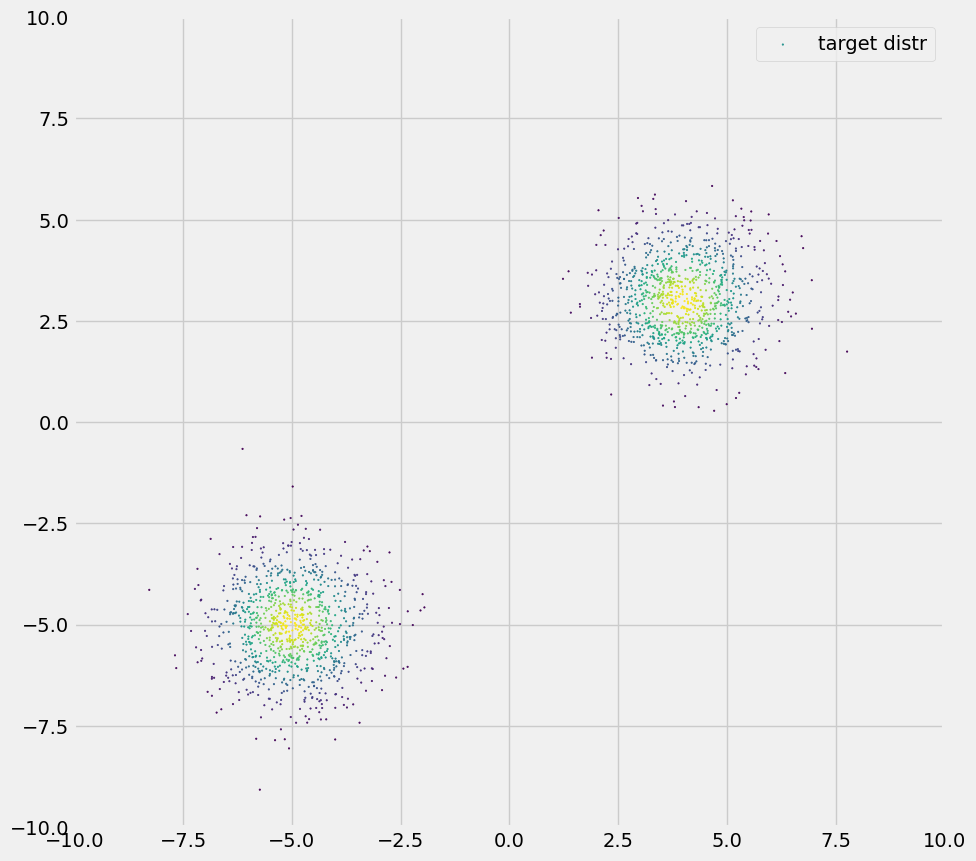

In [9]:
plt.figure(figsize=(10, 10))
plot_2d_dots(x, color=px, label='target distr')
plt.legend()
plt.show()

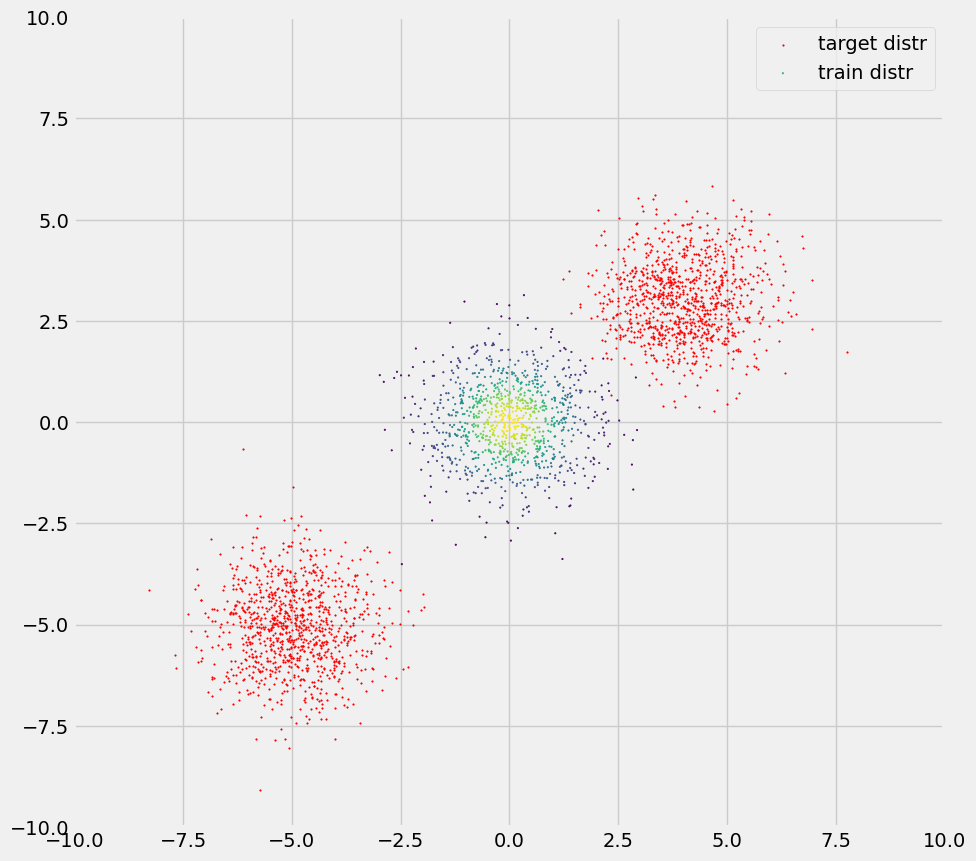

In [10]:
train_mu, train_sigma = get_parameters()

Q = create_distr(train_mu, train_sigma)
q_sample = sample(Q, 1000)
plt.figure(figsize=(10, 10))
plot_2d_dots(x, color='r', label='target distr')
plot_2d_dots(q_sample, color= Q.log_prob(q_sample).exp().detach(), label='train distr')

plt.legend()
plt.show()

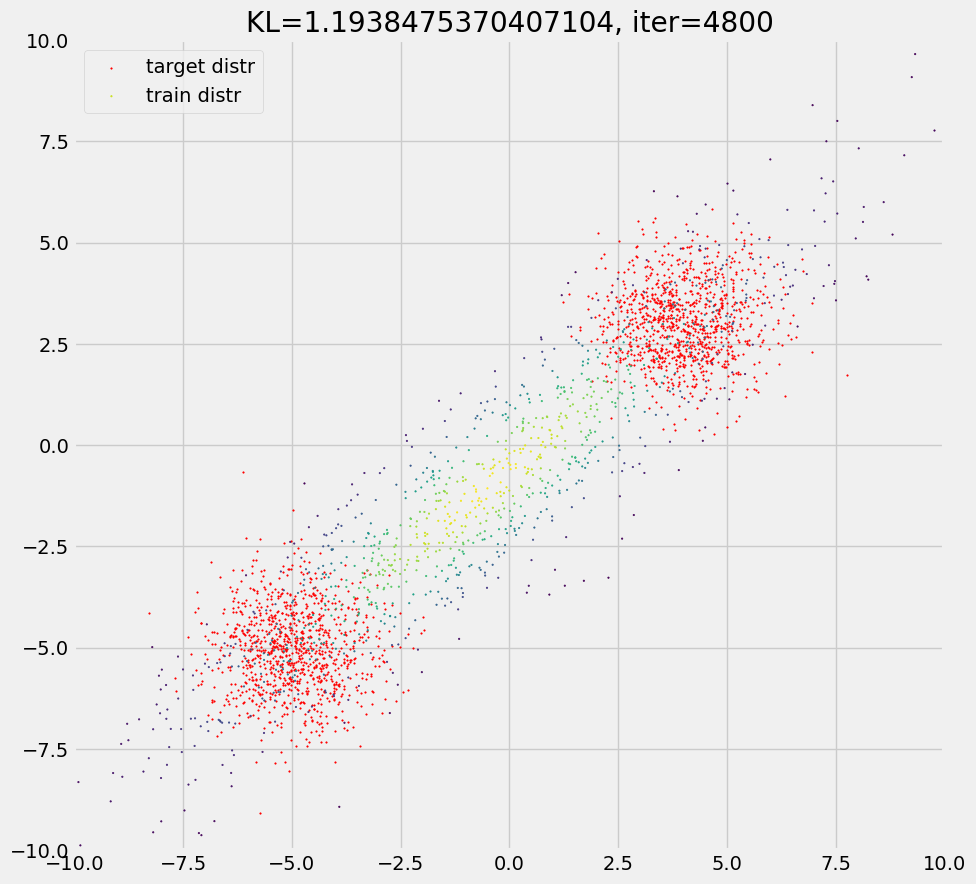

In [11]:
optim = torch.optim.SGD([train_mu, train_sigma], lr=0.1)

for i in range(5000):
    optim.zero_grad()
    Q = create_distr(train_mu, train_sigma)
    qx = Q.log_prob(x).exp()
    loss = kl_loss(px, qx, 1./px)
    loss.backward()
    optim.step()
    if i % 200 == 0:
        # plot pdfs
        clear_output(True)
        plt.figure(figsize=(10, 10))
        plt.title(f'KL={loss.item()}, iter={i}')
        plot_2d_dots(x, color='r', label='target distr')
        q_sample = sample(Q, 1000)
        plot_2d_dots(q_sample, color= Q.log_prob(q_sample).exp().detach(), label='train distr')
        plt.legend()
        plt.show()

### After Experiment 2 — Forward KL with a two-mode target

**What to notice**

- The blue target has two clusters, but the red model has only one Gaussian bump.
- The learned Gaussian usually becomes wide and sits between the modes, including low-density space in the middle.
- Forward KL makes missing target probability expensive, so it tries to cover both clusters. This is called **mass-covering**.

**What students should learn**

- The strange-looking result is not proof that KL is broken: the model family cannot express the true two-mode shape.
- Always separate two questions: “Is the objective appropriate?” and “Can the model represent the desired distribution?”

**Ask the class**

If you are allowed to draw only one ellipse around two islands, where must the ellipse go?


# Chapter 3: comparing KL and JS

### Jensen-Shannon divergence

For points sampled as $x\sim P$, the first term is estimated with ordinary Monte Carlo. The second term uses the importance weight $q(x)/p(x)$. In the code, this correction comes from the `1 / px` weight inside the shared `kl_loss` integrator.


In [12]:
def js_div(px, qx, weights=None):
    mixture = 0.5 * px + 0.5 * qx
    return (
        0.5 * kl_loss(px, mixture, weights)
        + 0.5 * kl_loss(qx, mixture, weights)
    )  # YOUR CODE


In [13]:
train_mu, train_sigma = get_parameters(1, 1)

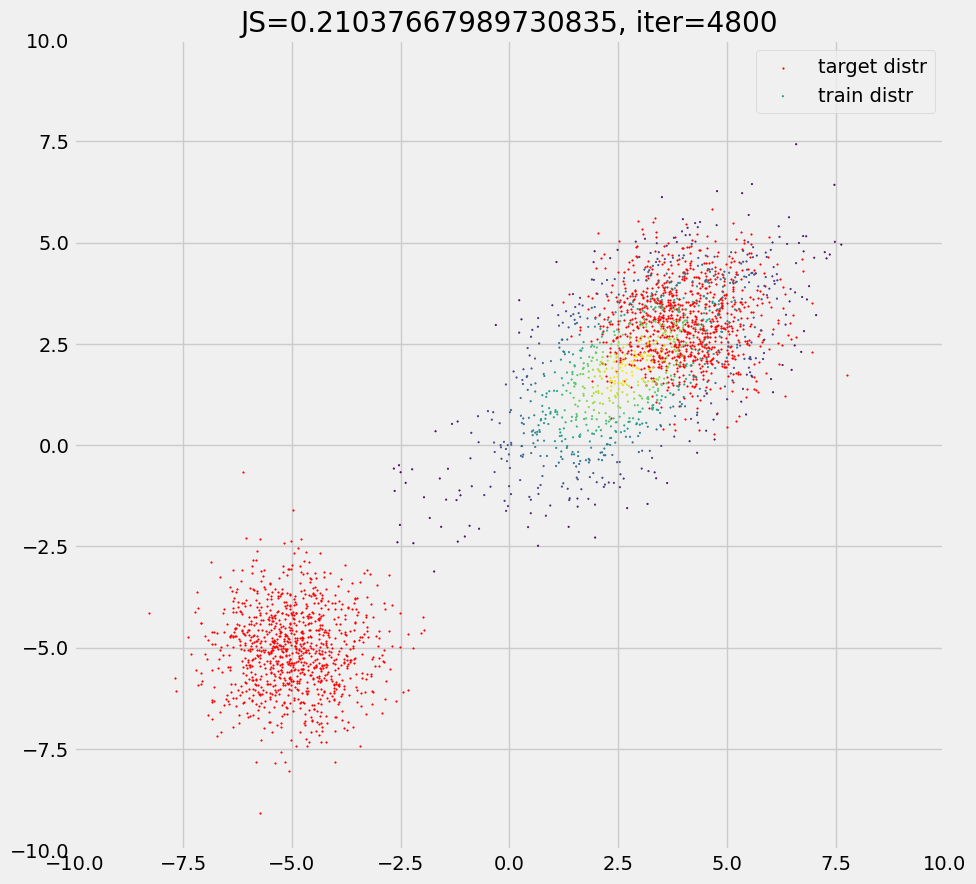

In [14]:
optim = torch.optim.SGD([train_mu, train_sigma], lr=0.1)

for i in range(5000):
    optim.zero_grad()
    Q = create_distr(train_mu, train_sigma)
    qx = Q.log_prob(x).exp()
    loss = js_div(px, qx, 1./px)
    loss.backward()
    optim.step()
    if i % 200 == 0:
        # plot pdfs
        clear_output(True)
        plt.figure(figsize=(10, 10))
        plt.title(f'JS={loss.item()}, iter={i}')
        plot_2d_dots(x, color='r', label='target distr')
        q_sample = sample(Q, 1000)
        plot_2d_dots(q_sample, color= Q.log_prob(q_sample).exp().detach(), label='train distr')
        plt.legend()
        plt.show()

### After Experiment 3 — Jensen–Shannon divergence

**What to notice**

- JS treats the two distributions symmetrically and remains finite in this example.
- The model is still a single Gaussian, so it still cannot create two separate peaks.
- The optimizer may find a different compromise from forward KL, and the result can depend on initialization and the Monte Carlo estimate.

**What students should learn**

- Symmetry fixes an interpretation issue, but it does not fix an underpowered model family.
- A mathematically well-defined objective can still have gradients that are inconvenient for learning.

**Ask the class**

Did changing the divergence give the model a second peak? Why or why not?


# Chapter 4: pointwise $L_2$ distance

### Least squares

For $x\sim P$, the weight $1/p(x)$ converts the sample average into a Monte Carlo estimate of the integral $\int (p(x)-q(x))^2\,dx$.

[The LSGAN paper](https://arxiv.org/abs/1611.04076) discusses a related least-squares idea, but the function below is a distance between density values, not the complete adversarial objective.


In [15]:
def l2_loss(px, qx, weights=None):
    if weights is None:
        weights = torch.ones_like(px)
    return torch.mean(weights * (px - qx).square())  # YOUR CODE


In [16]:
train_mu, train_sigma = get_parameters(1, 1)

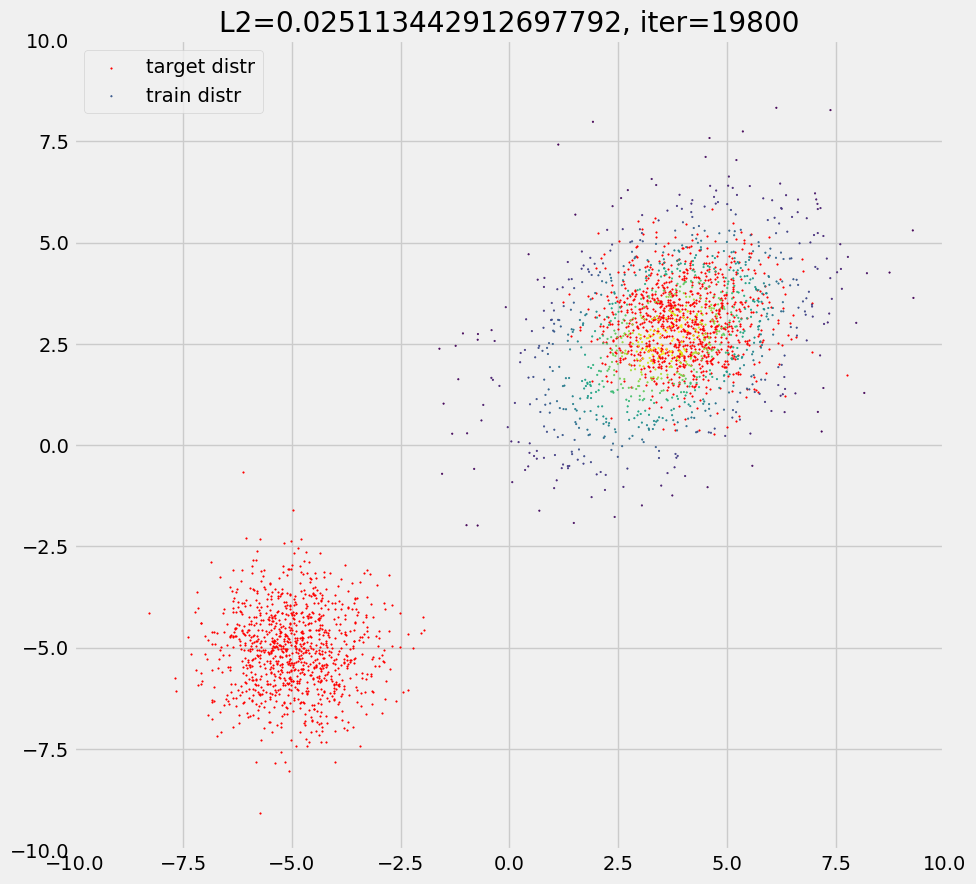

In [17]:
optim = torch.optim.SGD([train_mu, train_sigma], lr=0.5)

for i in range(20000):
    optim.zero_grad()
    Q = create_distr(train_mu, train_sigma)
    qx = Q.log_prob(x).exp()
    loss = l2_loss(px, qx, 1. / px)
    loss.backward()
    optim.step()
    if i % 200 == 0:
        # plot pdfs
        clear_output(True)
        plt.figure(figsize=(10, 10))
        plt.title(f'L2={loss.item()}, iter={i}')
        plot_2d_dots(x, color='r', label='target distr')
        q_sample = sample(Q, 1000)
        plot_2d_dots(q_sample, color= Q.log_prob(q_sample).exp().detach(), label='train distr')
        plt.legend()
        plt.show()

### After Experiment 4 — Pointwise L2 density loss

**What to notice**

- This loss compares the two density heights at sampled points; it is not comparing labels or individual image pixels.
- When the distributions barely overlap, many sampled points provide little information about how to move toward the target.
- Its fitted Gaussian can be different from the KL or JS solutions because every objective defines a different landscape for the optimizer.

**What students should learn**

- The choice of divergence changes both the preferred answer and the quality of the gradient used to reach it.
- This experiment is a density-level toy example; it is **not** the full least-squares GAN objective.

**Ask the class**

Look at the fitted mean and covariance. What kinds of mismatch does this loss appear to care about most?


## Optional chapter: gradient decay for separated distributions

The following integrals are evaluated on a uniform grid. We first use reverse KL, $D_{KL}(Q\|P)$, and then JS. When the distributions barely overlap, density clamping and JS saturation can produce a very weak learning signal.


In [18]:
mu1, sigma1 = -3, 0.5
mu2, sigma2 = -8, 0.5

target1 = distrs.Normal(mu1, sigma1)
target2 = distrs.Normal(mu2, sigma2)

x = torch.linspace(-10, 10, 1000)
px = 0.5 * target1.log_prob(x).exp() + 0.5 * target2.log_prob(x).exp()


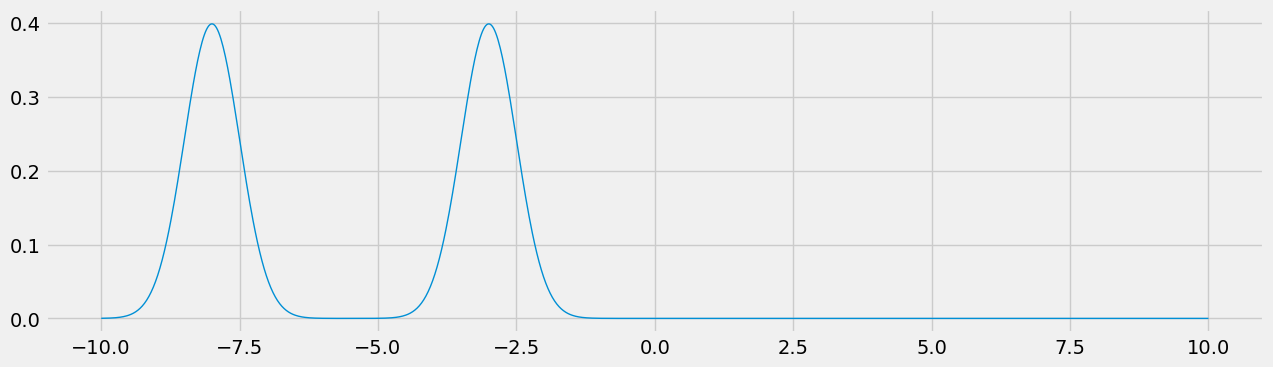

In [19]:
plt.figure(figsize=(14,4))

plt.plot(x.numpy(), px.numpy(), linewidth=1)
plt.show()


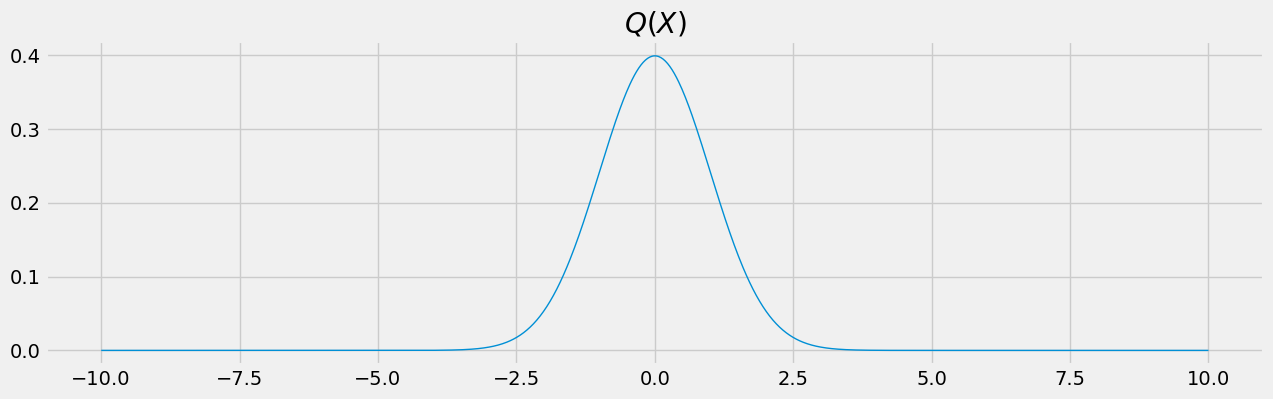

In [20]:
train_mu = torch.Tensor([0.0])
train_mu.requires_grad=True
train_sigma = torch.Tensor([1.0])
train_sigma.requires_grad=True

plt.figure(figsize=(14,4))
Q = distrs.Normal(train_mu, train_sigma)
qx = Q.log_prob(x).exp()
plt.plot(x.numpy(), qx.detach().numpy(), linewidth=1)
plt.title('$Q(X)$')
plt.show()

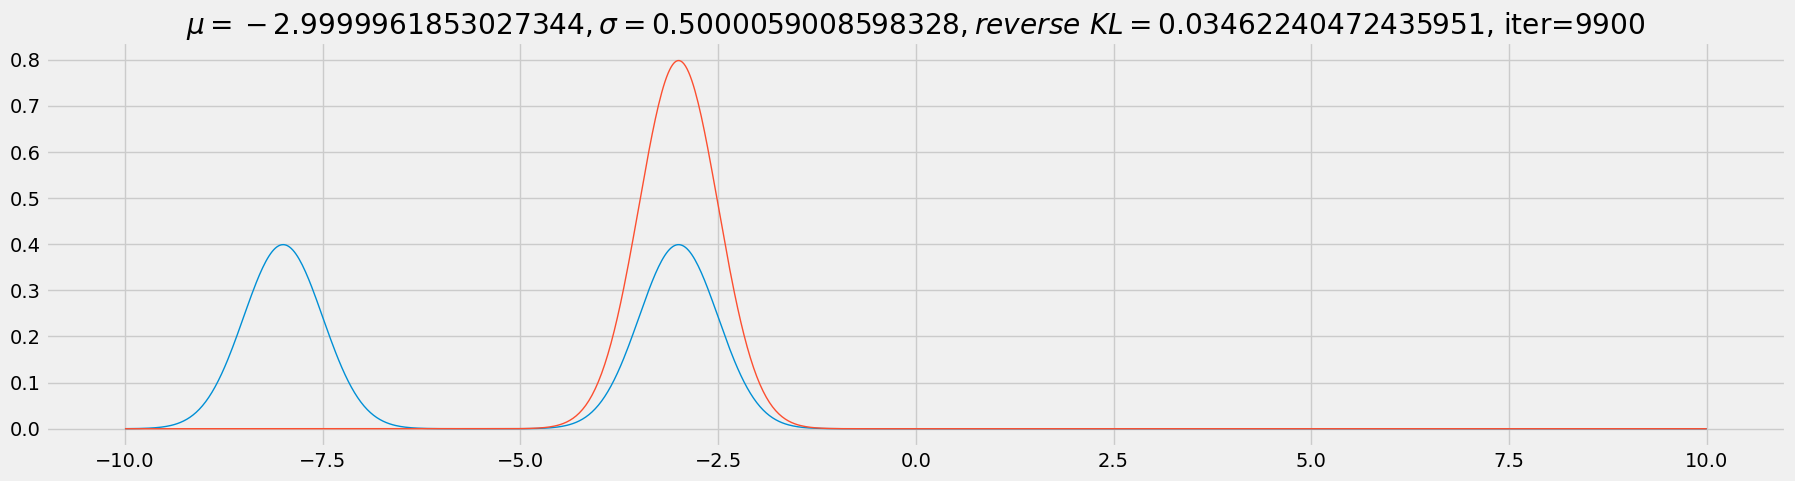

In [21]:
optim = torch.optim.SGD([train_mu, train_sigma], lr=0.1)
grads_mu = []
grads_sigma = []

for i in range(10000):
    optim.zero_grad()
    Q = distrs.Normal(train_mu, train_sigma)
    qx = Q.log_prob(x).exp()
    loss = kl_loss(qx, px)
    loss.backward()
    grads_mu.append(np.abs(train_mu.grad.item()))
    grads_sigma.append(np.abs(train_sigma.grad.item()))
    optim.step()
    if i % 300 == 0:
        # plot pdfs
        clear_output(True)
        plt.figure(figsize=(20, 5))
        plt.title(f'$\mu={train_mu.item()}, \sigma={train_sigma.item()}, reverse\ KL={loss.item()}$, iter={i}')
        plt.plot(x.numpy(), px.numpy(), linewidth=1)
        plt.plot(x.numpy(), qx.detach().numpy(), linewidth=1)
        plt.show()

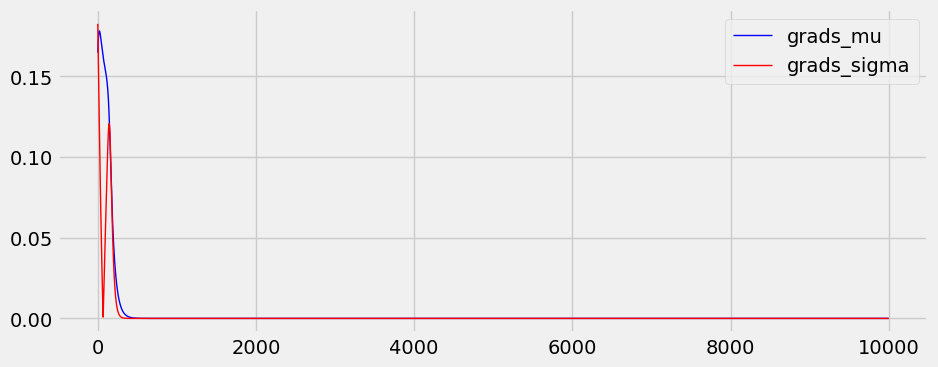

In [22]:
plt.figure(figsize=(10, 4))
plt.plot(grads_mu, c='blue', linewidth=1, label = 'grads_mu')
plt.plot(grads_sigma, c='red', linewidth=1, label = 'grads_sigma')
plt.legend()
plt.show()

### After Experiment 5 — Reverse KL gradients

**What to notice**

- Reverse KL usually prefers one high-density target region instead of covering both modes. This is called **mode-seeking**.
- Gradient magnitudes can be tiny when the model starts far from the target because the sampled regions have little useful overlap.
- A small gradient does **not** mean that the two distributions are close; it can mean that the objective gives a poor learning signal there.

**What students should learn**

- Changing the direction of KL changes what mistakes are expensive.
- Reverse KL strongly dislikes placing model probability where the target probability is tiny, so selecting one mode can be cheaper than filling the gap.

**Ask the class**

Would you rather cover every mode imperfectly, or make one mode very sharp and miss the other? Which KL direction encourages each behavior?


### Jensen-Shannon divergence


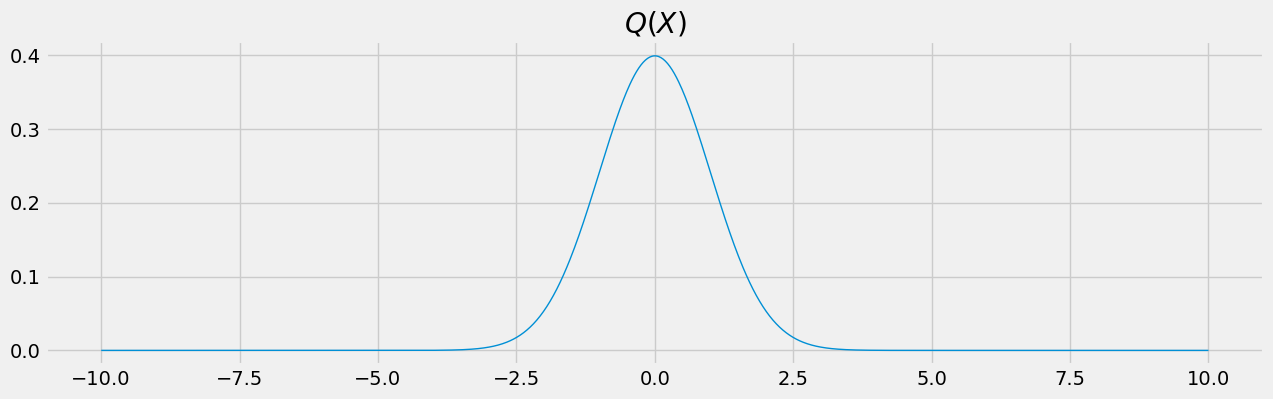

In [23]:
train_mu = torch.Tensor([0.0])
train_mu.requires_grad=True
train_sigma = torch.Tensor([1.0])
train_sigma.requires_grad=True

plt.figure(figsize=(14,4))
Q = distrs.Normal(train_mu, train_sigma)
qx = Q.log_prob(x).exp()
plt.plot(x.numpy(), qx.detach().numpy(), linewidth=1)
plt.title('$Q(X)$')
plt.show()

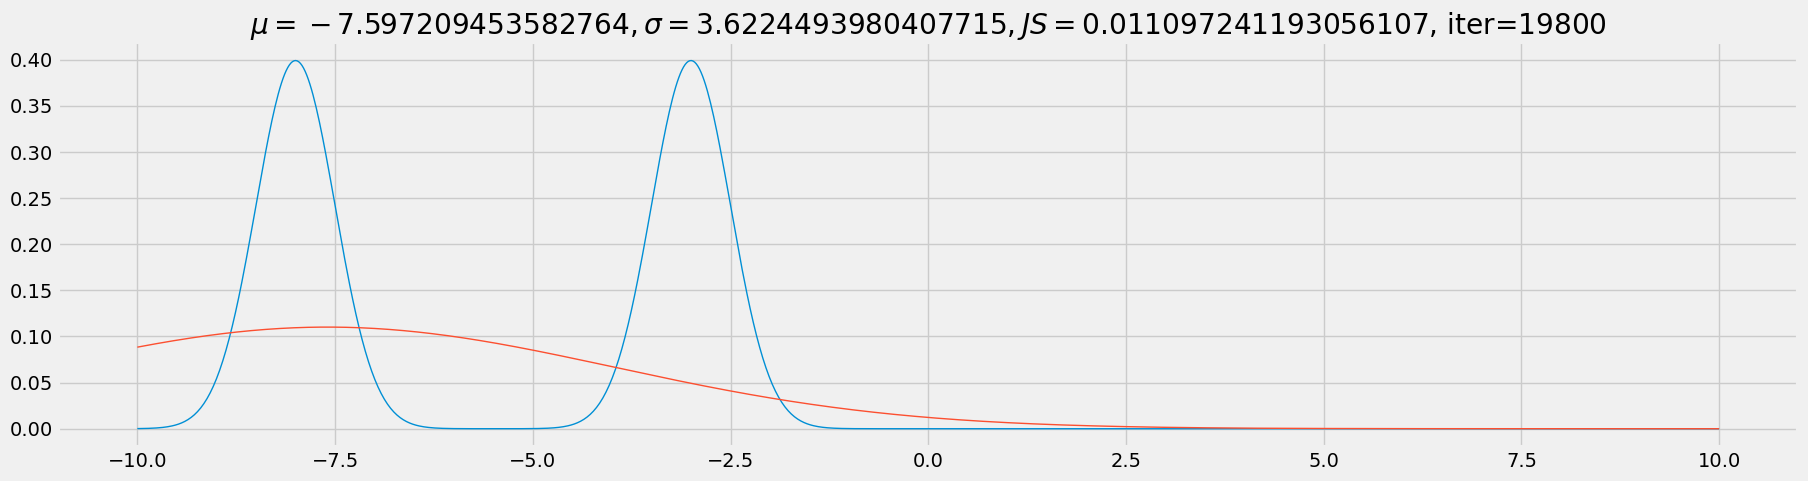

In [24]:
optim = torch.optim.SGD([train_mu, train_sigma], lr=0.5)
grads_mu = []
grads_sigma = []

for i in range(20000):
    optim.zero_grad()
    Q = distrs.Normal(train_mu, train_sigma)
    qx = Q.log_prob(x).exp()
    loss = js_div(px, qx)
    loss.backward()
    grads_mu.append(np.abs(train_mu.grad.item()))
    grads_sigma.append(np.abs(train_sigma.grad.item()))
    optim.step()
    if i % 300 == 0:
        # plot pdfs
        clear_output(True)
        plt.figure(figsize=(20, 5))
        plt.title(f'$\mu={train_mu.item()}, \sigma={train_sigma.item()}, JS={loss.item()}$, iter={i}')
        plt.plot(x.numpy(), px.numpy(), linewidth=1)
        plt.plot(x.numpy(), qx.detach().numpy(), linewidth=1)
        plt.show()

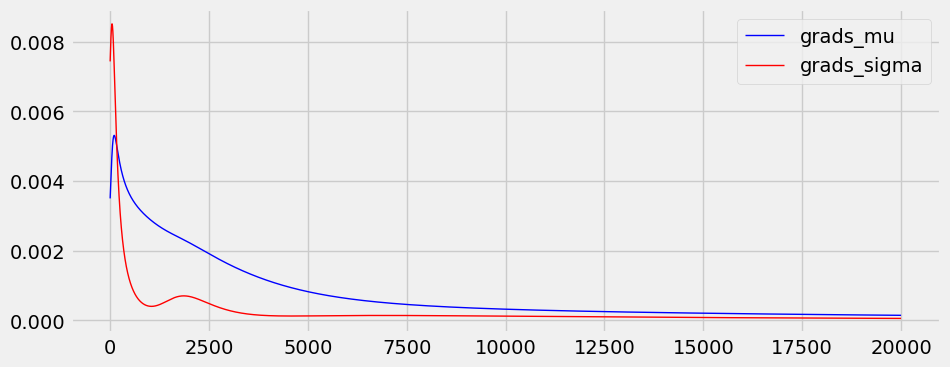

In [25]:
plt.figure(figsize=(10, 4))
plt.plot(grads_mu, c='blue', linewidth=1, label = 'grads_mu')
plt.plot(grads_sigma, c='red', linewidth=1, label = 'grads_sigma')
plt.legend()
plt.show()

### After Experiment 6 — JS gradients when distributions are far apart

**What to notice**

- The Jensen–Shannon value is bounded, but it can saturate when the two distributions barely overlap.
- When the objective saturates, the gradient can be weak even though the plotted distributions are visibly very different.
- The exact final position can vary because we estimate the objective from samples; the important evidence is the gradient curve.

**What students should learn**

- A finite, symmetric distance is not automatically easy to optimize.
- Weak gradients for separated distributions help explain why GAN training can stall and why Wasserstein distance is useful later in the course.

**Ask the class**

If the two distributions are obviously far apart, why might the optimizer still move only a little?
